<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Extract principal directions of variance using eigen-decomposition on standardized patient clinical data.


### Task 1: Synthesize and Standardize Multimodal Clinical Records


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(2024)
n_patients = 220

# Correlated clinical parameters
hb = np.random.normal(13.8, 1.4, n_patients)
rbc = 0.28 * hb + np.random.normal(0.8, 0.25, n_patients)
glucose = np.random.normal(98, 15, n_patients)
cholesterol = 0.5 * glucose + np.random.normal(140, 20, n_patients)
bmi = 0.12 * cholesterol + np.random.normal(10, 3, n_patients)

df_clinical = pd.DataFrame({
    'Hemoglobin': hb,
    'RBC_Count': rbc,
    'Fasting_Glucose': glucose,
    'Cholesterol': cholesterol,
    'BMI': bmi
})

# Standardize: (X - mu) / sigma
scaled_data = (df_clinical - df_clinical.mean()) / df_clinical.std()
print("Standardized Clinical Records (First 5 Rows):\n", scaled_data.head().round(3))


Standardized Clinical Records (First 5 Rows):
    Hemoglobin  RBC_Count  Fasting_Glucose  Cholesterol    BMI
0       1.561      1.283           -0.398       -0.152  0.642
1       0.666      0.945            1.413        2.126  1.510
2      -0.236     -0.686            0.010       -1.299 -1.218
3      -0.188     -0.620            0.695        1.007 -0.339
4       0.838      0.355            1.560        0.677  0.091


### Task 2: Compute Covariance and Correlation Heatmaps


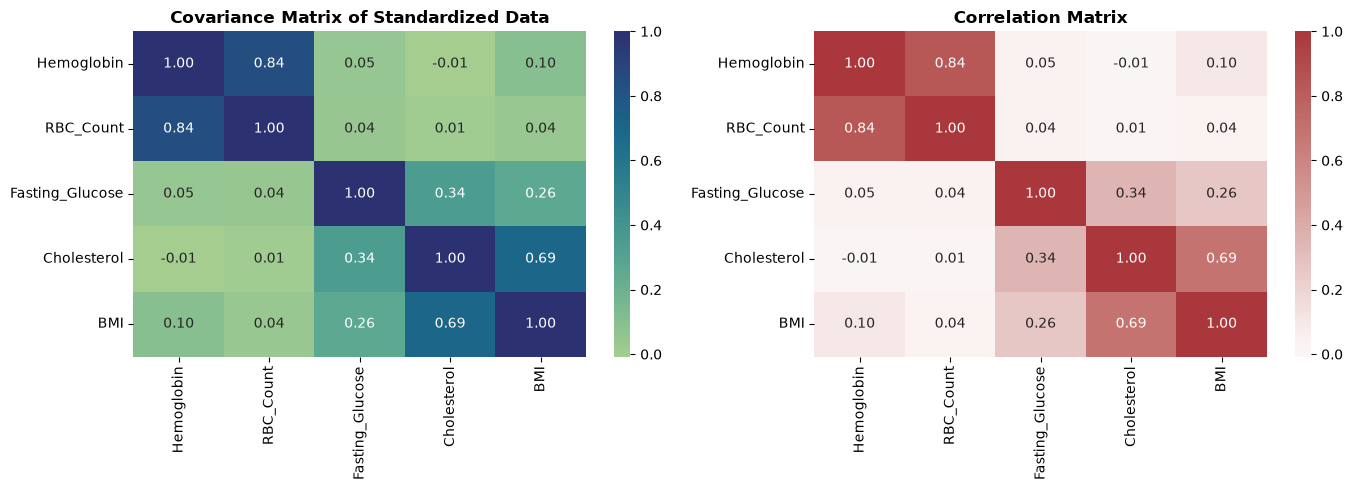

In [2]:
cov_mat = np.cov(scaled_data.T)
corr_mat = scaled_data.corr().values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cov_mat, annot=True, fmt=".2f", cmap="crest",
            xticklabels=df_clinical.columns, yticklabels=df_clinical.columns, ax=axes[0])
axes[0].set_title("Covariance Matrix of Standardized Data", fontweight='bold')

sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="vlag", center=0,
            xticklabels=df_clinical.columns, yticklabels=df_clinical.columns, ax=axes[1])
axes[1].set_title("Correlation Matrix", fontweight='bold')
plt.tight_layout()
plt.show()


### Task 3: Eigen-Decomposition and Variance Explanation


In [3]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_mat)

# Sort descending
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

var_explained = (eigenvalues / np.sum(eigenvalues)) * 100
cum_var = np.cumsum(var_explained)

print("Ranked Eigenvalues:", np.round(eigenvalues, 4))
for i, (ve, ce) in enumerate(zip(var_explained, cum_var), 1):
    print(f"Principal Axis {i}: {ve:.2f}% variance (Cumulative: {ce:.2f}%)")


Ranked Eigenvalues: [1.9627 1.7771 0.7983 0.3114 0.1505]
Principal Axis 1: 39.25% variance (Cumulative: 39.25%)
Principal Axis 2: 35.54% variance (Cumulative: 74.80%)
Principal Axis 3: 15.97% variance (Cumulative: 90.76%)
Principal Axis 4: 6.23% variance (Cumulative: 96.99%)
Principal Axis 5: 3.01% variance (Cumulative: 100.00%)


### Task 4: 2D Projection Scatter with Principal Axis Arrows


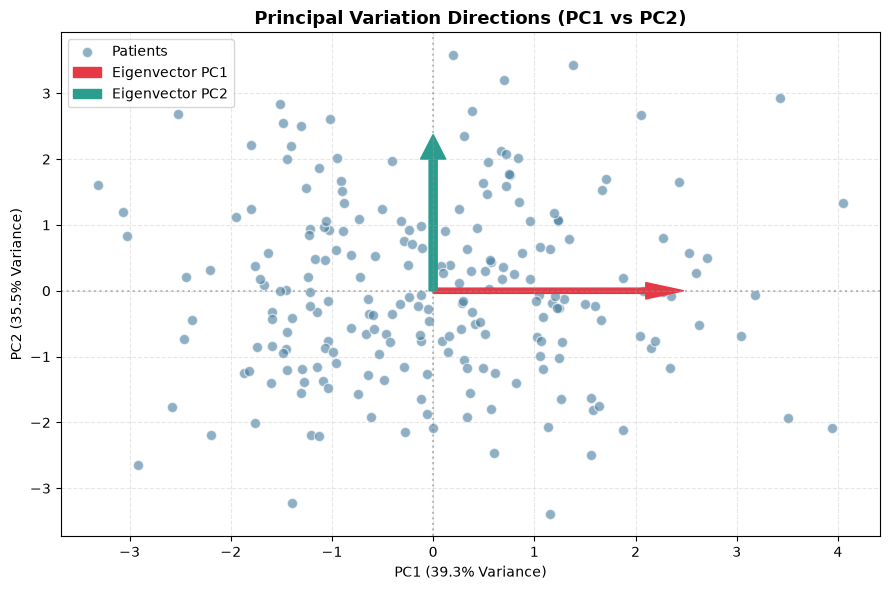

In [4]:
# Project data onto top 2 eigenvectors
projected_2d = np.dot(scaled_data.values, eigenvectors[:, :2])

plt.figure(figsize=(9, 6))
plt.scatter(projected_2d[:, 0], projected_2d[:, 1], color='#457b9d', alpha=0.6, edgecolors='w', s=55, label='Patients')

# Plot eigenvector directions
for i in range(2):
    length = np.sqrt(eigenvalues[i]) * 1.5
    plt.arrow(0, 0, length * (1 if i==0 else 0), length * (0 if i==0 else 1),
              color='#e63946' if i==0 else '#2a9d8f', width=0.08, head_width=0.25,
              label=f'Eigenvector PC{i+1}')

plt.title("Principal Variation Directions (PC1 vs PC2)", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({var_explained[0]:.1f}% Variance)")
plt.ylabel(f"PC2 ({var_explained[1]:.1f}% Variance)")
plt.axhline(0, color='gray', linestyle=':', alpha=0.5)
plt.axvline(0, color='gray', linestyle=':', alpha=0.5)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
